# $\zeta(5)$: historical constructions and new result

Samples are taken every 10 depths, normally through depth 300. Each computational example
prints the delta at its final sampled depth; the figure at the end plots
$\delta_N$ against $N$, where
$$D_N=-\log_{10}\left|\zeta(5)-\frac{p_N}{q_N}\right|,
\qquad \delta_N=\frac{D_N}{\log_{10}q_N}-1.$$
Here $p_N/q_N$ is reduced. Accuracy digits measure absolute approximation error.

Run the cells in order (Python 3.11+). The CMF encodings come from the supplied
exploratory notebooks and local supplementary material. Published bounds and the
finite-depth $\delta_N$ values are different quantities; the computations below do
not by themselves prove a published irrationality-measure bound.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 matplotlib==3.11.2

## Setup

Each example constructs a CMF, walks a trajectory with ramanujantools, reads
$p_N/q_N$ off the first column $(s_0,\ldots,s_6)$ of the dual walk, and computes
$\delta_N$. The walks and the approximants are exact.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from flint import fmpq
from ramanujantools import Position
from ramanujantools.cmf.pfq import pFq
from ramanujantools.flint_core.numeric_matrix import NumericMatrix

sys.set_int_max_str_digits(0)
with ctx.workdps(81_000):  # q_N reaches about 18,000 digits at depth 300 (Brown-Zudilin)
    ZETA5 = arb(5).zeta()
DEPTHS = list(range(10, 3001, 10))
n = sp.Symbol("n")
x = sp.symbols("x0:8")
y = sp.symbols("y0:7")

# Brown-Zudilin's projection: p_N = NUMERATOR . s and q_N = DENOMINATOR . s.
NUMERATOR = [fmpq(16342893984375, 8), fmpq(7888732953125, 2), fmpq(24573697734375, 8),
             1206481062500, fmpq(1912606640625, 8), fmpq(76504265625, 4), 0]
DENOMINATOR = [1969765000000, fmpq(15220831421875, 4), fmpq(11858161171875, 4),
               fmpq(2329422984375, 2), fmpq(461663671875, 2), 18466546875, 0]
results = {}


def delta(approximant):
    """delta with |ζ(5) - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |ζ(5) - p/q|
        error = abs(ZETA5 - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

## 1. Brown–Zudilin (2022)

F. Brown and W. Zudilin, *On cellular rational approximations to
$\zeta(5)$*, arXiv:2210.03391 (2022).
[Preprint](https://arxiv.org/abs/2210.03391).

**CMF:** ${}_8F_7(1)$ · **Start:** $(5,2,2,2,2,2,2,2;4,4,4,4,4,4,4)$ ·
**Direction:** $(41,17,16,15,14,13,12,11;24,25,26,27,28,29,30)$.
We use the inverse-transpose walk and the exact two-row projection stored
with the original construction.

In [3]:
cmf = pFq(8, 7, 1)
start = dict(zip(x + y, [5, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4]))
trajectory = dict(zip(x + y, [41, 17, 16, 15, 14, 13, 12, 11, 24, 25, 26, 27, 28, 29, 30]))
depths = list(range(10, 301, 10))
# The dual walk is the inverse transpose of the walk. The symbolic inverse of this
# rank-7 matrix is slow, so the walk is inverted numerically (FLINT).
matrix = cmf.trajectory_matrix(trajectory, start)
walks = NumericMatrix.walk(matrix, Position({n: 1}), depths, Position({n: 0}))
duals = [W.inv().transpose() for W in walks]
approximants = [sum(c * D[j, 0] for j, c in enumerate(NUMERATOR))
                / sum(c * D[j, 0] for j, c in enumerate(DENOMINATOR)) for D in duals]
deltas = [delta(r) for r in approximants]
results["Brown–Zudilin (2022)"] = (depths, deltas)
print(f"delta at depth 300: {deltas[-1]:.9f}")

delta at depth 300: -0.133965704


## 2. New ${}_8F_7(1)$ trajectory

This is the improved $\zeta(5)$ trajectory recorded by the local depth-scan
experiment `improved_m0_131812537914`.

**CMF:** ${}_8F_7(1)$ · **Start:** $(5,2,2,2,2,2,2,2;4,4,4,4,4,4,4)$ ·
**Direction:** $(164,67,63,59,56,52,48,44;97,101,105,108,112,116,120)$.
We use the inverse-transpose walk and the same exact projection as the
Brown–Zudilin construction. Because this trajectory is much more expensive,
this example is sampled through depth 100.

In [4]:
cmf = pFq(8, 7, 1)
start = dict(zip(x + y, [5, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4]))
trajectory = dict(zip(x + y, [164, 67, 63, 59, 56, 52, 48, 44, 97, 101, 105, 108, 112, 116, 120]))
depths = list(range(10, 101, 10))
# The dual walk is the inverse transpose of the walk. The symbolic inverse of this
# rank-7 matrix is slow, so the walk is inverted numerically (FLINT).
matrix = cmf.trajectory_matrix(trajectory, start)
walks = NumericMatrix.walk(matrix, Position({n: 1}), depths, Position({n: 0}))
duals = [W.inv().transpose() for W in walks]
approximants = [sum(c * D[j, 0] for j, c in enumerate(NUMERATOR))
                / sum(c * D[j, 0] for j, c in enumerate(DENOMINATOR)) for D in duals]
deltas = [delta(r) for r in approximants]
results["New ${}_8F_7(1)$ trajectory"] = (depths, deltas)
print(f"delta at depth 100: {deltas[-1]:.9f}")

delta at depth 100: -0.133014805


## All constructions

$\delta_N$ against the walk depth $N$.

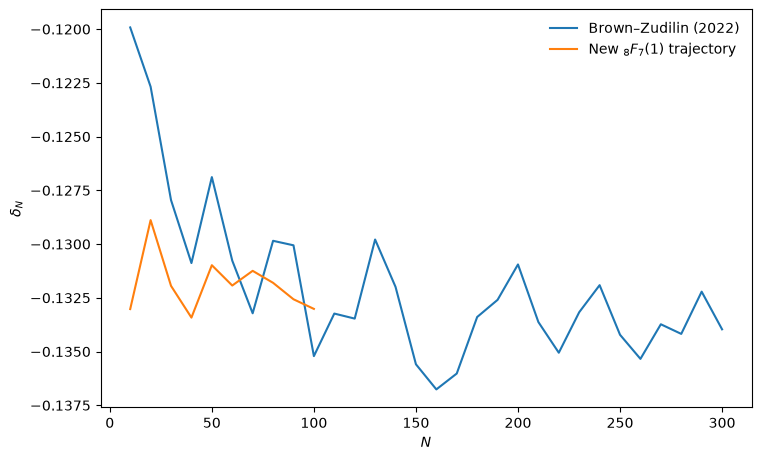

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Historical overview

| Construction | Role | Notebook coverage |
|:--|:--|:--|
| Brown–Zudilin (2022) | Published cellular rational approximation | CMF and exact projection above |
| This work | Improved local ${}_8F_7(1)$ trajectory | New CMF trajectory above |

No irrationality measure for $\zeta(5)$ is currently known: its irrationality
itself remains open. Accordingly, this table compares finite-depth approximation
exponents rather than published upper bounds for $\mu(\zeta(5))$.